# Questão 2 — MLP para qualidade de vinhos
## Dados, hipóteses, comparação e decisão

Este notebook atende à Q2 da lista: classificar Wine Quality em baixa (0–4),
média (5–6) e alta (7–10), analisar os dados e apresentar arquitetura, curvas
de erro, matriz de confusão, accuracy, precision, recall e F1.

O objetivo experimental é melhorar o **F1 macro** sem esconder o comportamento
de cada classe. F1 macro dá o mesmo peso às três classes; accuracy continua
sendo apresentada. Mais neurônios, pesos de classe e regularização são
**hipóteses testadas**, não garantias de melhoria.

**Como usar no Colab:** execute tudo, de cima para baixo. O modo completo faz
54 treinos de validação e até 6 treinos finais, com parada antecipada.
O tempo depende do ambiente. Cada treino concluído é registrado em disco:
se a execução parar, a mesma configuração pode aproveitar esses registros.
O disco temporário do Colab se perde quando a sessão é apagada; para persistir,
altere PASTA para uma pasta do Drive já montada.

Não há métricas inventadas ou copiadas de versões anteriores. As tabelas,
figuras, modelo selecionado e texto de interpretação serão produzidos pela
execução. O modo de verificação usa poucos treinos e não serve para apresentar
resultados de qualidade do modelo.

## Como estudar este notebook

O texto acompanha três pilares: **dados** (o que representa cada exemplo e como foi preparado), **arquitetura** (como a rede transforma entradas em respostas) e **resultados** (o que a avaliação permite concluir). Antes de cada célula há uma explicação de suas operações, decisões e saídas esperadas. As saídas já salvas permitem ler o trabalho sem executar novos treinamentos.

**Estado dos resultados.** As células de código e suas saídas foram preservadas da execução fornecida. Esta revisão acrescenta documentação; não executa novos experimentos. Uma saída salva é um registro do experimento, não mantém os modelos Python vivos na memória. Para utilizar variáveis ou gerar novas previsões no Colab, execute as células em ordem. Versões, dispositivo e operações aleatórias podem causar diferenças em uma nova execução. Os números descritos no texto são os da execução registrada e devem ser revistos se os modelos forem retreinados.

### Fundamentos necessários para acompanhar as células

- **Exemplo ou observação:** uma entrada acompanhada da resposta conhecida. Um lote reúne vários exemplos para uma atualização dos pesos.
- **Atributo:** uma informação de entrada. O **alvo** é aquilo que queremos prever. Atributos não devem conter a própria resposta ou informações indisponíveis no momento de prever.
- **Neurônio e camada densa:** cada neurônio calcula uma combinação ponderada das entradas, soma um viés e aplica uma ativação. Em uma camada densa, cada neurônio recebe todas as saídas da camada anterior. Pesos e vieses são os parâmetros aprendidos.
- **Ativação:** introduz uma transformação não linear. ReLU calcula `max(0, x)`; Tanh é suave e varia de −1 a 1; Sigmoid varia de 0 a 1. Uma saída linear não impõe esses limites. A escolha depende da tarefa e deve ser avaliada no contexto do treinamento.
- **Função de perda:** transforma a diferença entre resposta e previsão em um número a minimizar. Uma métrica de avaliação pode coincidir com a perda, mas também pode medir outro aspecto do desempenho.
- **Gradiente e retropropagação:** o gradiente indica como a perda varia em relação a cada parâmetro. A retropropagação calcula esses gradientes ao percorrer as operações da rede em sentido inverso.
- **Adam:** otimizador que usa estimativas acumuladas dos gradientes e de seus quadrados para atualizar os parâmetros. A taxa de aprendizado controla a escala dos ajustes. Adam e retropropagação cumprem funções complementares.
- **Época:** uma passagem pelos exemplos de treino. **Batch size** é a quantidade de exemplos em cada lote. Mais épocas aumentam o trabalho de otimização, mas não garantem melhor desempenho em dados novos.
- **Early stopping:** monitora uma perda em dados separados, espera um número de épocas sem melhora e interrompe o treinamento. Quando solicitado, restaura os pesos da melhor época monitorada. A técnica limita o sobreajuste, mas não garante eliminá-lo.
- **Semente:** controla parte da aleatoriedade, como divisão e inicialização. Repetir sementes ajuda a observar a sensibilidade do resultado; não substitui testar em amostras independentes.
- **Generalização e sobreajuste:** generalizar é manter desempenho em dados não usados para ajustar os pesos. Quando o treino melhora e a avaliação separada estagna ou piora, há indício de que parte do aprendizado deixou de se transferir.

**Como ler “média ± desvio-padrão”.** A média resume as repetições, e o desvio descreve sua dispersão. É necessário verificar se as repetições mudam a inicialização ou também a divisão dos dados. Esse símbolo não representa variação por época nem um intervalo de confiança.

## Como interpretar uma classificação

Uma classe prevista é escolhida pela maior saída da Softmax. Para cada classe, **TP** são acertos nessa classe, **FP** são exemplos de outras classes previstos como ela e **FN** são exemplos dela previstos como outra.

$$\mathrm{precision}=\frac{TP}{TP+FP},\qquad
\mathrm{recall}=\frac{TP}{TP+FN},\qquad
F1=\frac{2\,\mathrm{precision}\,\mathrm{recall}}{\mathrm{precision}+\mathrm{recall}}.$$

Precision responde “quantas previsões desta classe estavam certas?”; recall responde “quantos casos reais dela foram encontrados?”. F1 combina as duas. **Accuracy** é a proporção total de acertos. **Macro** calcula a métrica por classe e tira a média sem favorecer classes grandes; **weighted** pondera pela quantidade de exemplos. A média macro de F1 é a média dos F1 individuais, não o F1 calculado a partir de precision e recall macro.

Na matriz de confusão, linhas são classes reais e colunas são previstas. A diagonal contém acertos. A normalização por linha divide cada linha pela quantidade real da classe; sua diagonal equivale ao recall por classe. O suporte (`support` ou `n`) é o número de exemplos reais.

A **entropia cruzada** penaliza uma baixa probabilidade atribuída à classe correta: para um exemplo, a perda é $-\log p_{correta}$. A variante `sparse` aceita rótulos inteiros em vez de vetores com um indicador por classe. Uma Softmax pode gerar valor alto e estar errada; os escores não foram calibrados para garantir que 0,9 corresponda a 90% de acertos.

## 1. O que muda e por quê

| Decisão | Motivo e limite |
|---|---|
| Usar tintos e brancos, com indicação do tipo | Aproveitar as duas bases; testar retirar o tipo para medir sua utilidade |
| Retirar duplicatas exatas | Impedir que cópias idênticas facilitem a avaliação; duplicidade de linhas não prova identidade de vinhos físicos |
| Agrupar medições físico-químicas idênticas | Manter no mesmo conjunto registros com as mesmas entradas, mesmo quando as notas divergem |
| Retirar quality e categoria das entradas | A nota constrói o alvo; fornecê-la seria vazamento da resposta |
| Separar teste antes da exploração detalhada | Avaliar o modelo escolhido ao final deste protocolo |
| Três partições de validação no desenvolvimento | Reduzir a dependência de uma única divisão favorável |
| Monitoramento interno para early stopping | O bloco que avalia uma candidata não escolhe sua época de parada |
| Escalonamento e seleção de atributos dentro de cada treino | Evitar que as estatísticas de validação e teste influenciem a preparação |
| Comparar pesos 0, moderados e balanceados | A classe rara pode ganhar recall e perder precisão; medir o efeito |
| Comparar quatro arquiteturas | Avaliar uma camada, duas camadas menores, a referência e uma rede mais larga |
| Testar uma alteração por vez na segunda etapa | Atribuir a diferença à técnica aplicada à mesma configuração |
| Salvar históricos e modelos | Gerar curvas com o treino realmente avaliado, sem um treino extra para desenhá-las |

A partição e o pré-processamento diferem do notebook antigo. Por isso, a comparação
correta é com a MLP de referência **reexecutada neste protocolo**, não diretamente
com a accuracy antiga de 0,625. Esta base já foi explorada no projeto: o teste
fica reservado nesta execução, mas não é uma validação externa.

### Leitura da célula: configurar o protocolo e registrar o ambiente

Importamos componentes para baixar dados, construir pipelines, treinar redes, calcular métricas e salvar artefatos. O modo completo configura três folds, até 150 épocas, lote 64, paciência 18 e três sementes finais. A margem de 0,005 em F1 é uma tolerância prática de meio ponto percentual, não um teste estatístico.

`PASTA` organiza figuras, cache e modelos. `salvar_json` grava primeiro em arquivo temporário para reduzir o risco de registros incompletos. `figura` salva e mostra a mesma figura. Versões são registradas porque bibliotecas podem alterar detalhes de execução. Este notebook já tem saídas; o cache externo só será aproveitado se os arquivos também estiverem disponíveis no ambiente de execução.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import io, json, hashlib, zipfile, urllib.request, shutil, time, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import sklearn
import joblib
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, log_loss,
)

MODO = "completo"  # "verificacao" somente para conferir o funcionamento técnico
COMPLETO = MODO == "completo"
SEMENTE_DIVISAO = 20261117
N_FOLDS = 3 if COMPLETO else 2
MAX_EPOCAS = 150 if COMPLETO else 2
PACIENCIA = 18
LOTE = 64
SEMENTES_FINAIS = [42, 123, 2026] if COMPLETO else [42]
MARGEM_PRATICA = 0.005  # meio ponto percentual de F1 macro, não teste estatístico
PASTA = Path("resultados_q2" if COMPLETO else "tmp/q2_verificacao")
PASTA.mkdir(parents=True, exist_ok=True)
for nome in ["figuras", "cache", "modelos"]:
    (PASTA / nome).mkdir(exist_ok=True)
NOMES = ["baixa", "média", "alta"]
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 25)

VERSOES = {
    "python": platform.python_version(), "tensorflow": tf.__version__,
    "keras": keras.__version__, "sklearn": sklearn.__version__,
    "numpy": np.__version__, "pandas": pd.__version__,
}
print("Modo:", MODO, "| versões:", VERSOES)
if not COMPLETO:
    print("ATENÇÃO: execução técnica curta; não usar as métricas como resultado final.")

def salvar_json(path, objeto):
    def converter(valor):
        if isinstance(valor, np.generic): return valor.item()
        if isinstance(valor, np.ndarray): return valor.tolist()
        if isinstance(valor, Path): return str(valor)
        raise TypeError(type(valor).__name__)
    path = Path(path)
    temporario = path.with_suffix(path.suffix + ".tmp")
    temporario.write_text(json.dumps(objeto, ensure_ascii=False, indent=2,
                                    default=converter), encoding="utf-8")
    temporario.replace(path)

def figura(nome):
    plt.savefig(PASTA / "figuras" / f"{nome}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

Modo: completo | versões: {'python': '3.13.18', 'tensorflow': '2.21.0', 'keras': '3.13.2', 'sklearn': '1.6.1', 'numpy': '2.4.6', 'pandas': '2.2.3'}


## 2. Origem, significado e limpeza dos dados

Wine Quality contém medições físico-químicas e uma avaliação sensorial de qualidade.
Uma linha é uma observação, não necessariamente um vinho único identificável.
Usamos os arquivos tinto e branco e registramos o tipo como 0 ou 1.

As 11 medidas são acidez fixa, acidez volátil, ácido cítrico, açúcar residual,
cloretos, dióxido de enxofre livre e total, densidade, pH, sulfatos e álcool.
O tipo acrescenta uma entrada: inicialmente a MLP recebe **12 atributos**.
A saída são três probabilidades. As faixas seguem o enunciado, não foram
ajustadas para favorecer as métricas.

Removemos linhas idênticas considerando também a nota e o tipo. Notas diferentes
para as mesmas medições são preservadas: são informação sobre a ambiguidade do
problema, não autorização para escolher o rótulo que favoreça o modelo.

### Leitura da célula: origem, limpeza, alvo e grupos

Baixamos o ZIP oficial da UCI e reunimos 1.599 tintos com 4.898 brancos. O hash SHA-256 identifica o conteúdo do download; ele não é uma métrica do modelo. Retiramos 1.177 duplicatas exatas, ficando com 5.320 linhas. A duplicidade se refere a registros, sem provar que se trata do mesmo vinho físico.

As notas viram baixa (0–4), média (5–6) e alta (7–10), codificadas como 0, 1 e 2. `quality` e `categoria` ficam fora das entradas. O tipo branco/tinto acrescenta a décima segunda entrada.

Agrupamos pela igualdade das 11 medições físico-químicas, inclusive se o tipo diferir: 5.318 grupos. Isso não remove novas linhas, apenas obriga perfis iguais a permanecer juntos nas divisões. A verificação de categorias divergentes encontra zero nesta execução. Ela não autoriza escolher ou corrigir rótulos por conveniência.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"
arquivo_zip = PASTA / "wine_quality_uci.zip"
if not arquivo_zip.exists():
    with urllib.request.urlopen(URL, timeout=90) as resposta:
        arquivo_zip.write_bytes(resposta.read())
conteudo = arquivo_zip.read_bytes()
HASH_DADOS = hashlib.sha256(conteudo).hexdigest()
with zipfile.ZipFile(io.BytesIO(conteudo)) as pacote:
    tinto = pd.read_csv(pacote.open("winequality-red.csv"), sep=";")
    branco = pd.read_csv(pacote.open("winequality-white.csv"), sep=";")
tinto["tipo_branco"] = 0
branco["tipo_branco"] = 1
dados_brutos = pd.concat([tinto, branco], ignore_index=True)
NUMERICAS = [c for c in tinto.columns if c not in ["quality", "tipo_branco"]]
PREDITORES = NUMERICAS + ["tipo_branco"]
n_duplicatas = int(dados_brutos.duplicated().sum())
dados = dados_brutos.drop_duplicates().reset_index(drop=True)
if dados["quality"].isna().any() or not dados["quality"].between(0, 10).all():
    raise ValueError("Notas ausentes ou fora do domínio 0–10; inspecione a fonte.")
dados["categoria"] = np.select(
    [dados["quality"] <= 4, dados["quality"] <= 6], [0, 1], default=2
).astype("int64")
# Mesmo vetor físico-químico fica no mesmo grupo, inclusive entre tipos.
grupos = dados.groupby(NUMERICAS, sort=False, dropna=False).ngroup().to_numpy()
X = dados[PREDITORES].copy()
y = dados["categoria"].to_numpy()
assert "quality" not in X and "categoria" not in X
ambiguos = pd.DataFrame({"grupo": grupos, "classe": y}).groupby("grupo")["classe"].nunique()
print(f"Tintos: {len(tinto)} | brancos: {len(branco)} | total: {len(dados_brutos)}")
print(f"Duplicatas exatas removidas: {n_duplicatas} | observações mantidas: {len(dados)}")
print("Grupos de medições idênticas:", len(np.unique(grupos)))
print("Grupos com categorias divergentes:", int((ambiguos > 1).sum()))
print("SHA-256 do arquivo UCI:", HASH_DADOS)

Tintos: 1599 | brancos: 4898 | total: 6497
Duplicatas exatas removidas: 1177 | observações mantidas: 5320
Grupos de medições idênticas: 5318
Grupos com categorias divergentes: 0
SHA-256 do arquivo UCI: 3ed56667f4b828242bd732d7d1dd7f2861e54432239d7fa63877014cbb0304d4


## 3. Separação dos dados: quem faz o quê

Primeiro reservamos aproximadamente 20% como teste, usando o primeiro bloco de
uma divisão em cinco partes com semente fixada antes dos resultados. O restante
é o **desenvolvimento**. A estratificação tenta manter as proporções das classes;
o agrupamento impede que medições idênticas cruzem as divisões. As proporções
podem variar um pouco para respeitar os grupos.

Dentro do desenvolvimento, cada candidata passa por três avaliações:

| Conjunto em cada avaliação | Função |
|---|---|
| Treino | Ajustar escalonador, pesos de classe, seleção de atributos e pesos da rede |
| Monitoramento interno | Acompanhar a perda e decidir quando interromper o treino |
| Validação da candidata | Calcular F1 macro que compara as configurações |
| Teste reservado | Avaliar somente a configuração escolhida e referências ao final |

O monitoramento usa aproximadamente 20% da parte de treino de cada avaliação.
Essa separação adicional evita usar a mesma parcela para escolher a época e
depois tratá-la como avaliação independente da candidata.
As três pontuações variam com a divisão e a inicialização; seu desvio-padrão
não é um intervalo de confiança nem três testes externos.

### Leitura da célula: quatro papéis distintos na avaliação

Reservamos 1.063 observações para teste e 4.257 para desenvolvimento. StratifiedGroupKFold tenta preservar proporções de classe sem quebrar grupos; por isso tamanhos e proporções podem diferir ligeiramente do ideal.

No desenvolvimento, três folds alternam a parte que avalia as candidatas. Em cada fold, parte do restante é separada para monitoramento interno do early stopping. As contagens salvas são treino/monitoramento/validação: 2.269/568/1.420; 2.271/568/1.418; 2.271/567/1.419. Asserções verificam que grupos não atravessam essas partes e que as classes estão representadas.

Esse desenho distingue escolher a época de escolher a arquitetura. Não é uma validação cruzada externa completa de cinco testes: apenas um bloco externo foi reservado para a avaliação final. Os índices são salvos para auditar as divisões.

In [3]:
def dividir_monitoramento(indices, seed):
    divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    a, b = next(divisor.split(X.iloc[indices], y[indices], grupos[indices]))
    return indices[a], indices[b]

externa = StratifiedGroupKFold(n_splits=5, shuffle=True,
                              random_state=SEMENTE_DIVISAO)
idx_dev, idx_teste = next(externa.split(X, y, grupos))
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True,
                         random_state=SEMENTE_DIVISAO + 1)
DIVISOES = []
for fold, (a, b) in enumerate(cv.split(X.iloc[idx_dev], y[idx_dev], grupos[idx_dev])):
    idx_fit, idx_monitor = dividir_monitoramento(idx_dev[a], SEMENTE_DIVISAO + 10 + fold)
    idx_avaliacao = idx_dev[b]
    listas = [idx_fit, idx_monitor, idx_avaliacao, idx_teste]
    for j in range(len(listas)):
        assert set(np.unique(y[listas[j]])) == {0, 1, 2}
        for k in range(j + 1, len(listas)):
            assert not set(grupos[listas[j]]) & set(grupos[listas[k]])
    DIVISOES.append((idx_fit, idx_monitor, idx_avaliacao))
idx_final_fit, idx_final_monitor = dividir_monitoramento(idx_dev, SEMENTE_DIVISAO + 99)
print(f"Desenvolvimento: {len(idx_dev)} | teste reservado: {len(idx_teste)}")
display(pd.DataFrame([
    {"fold": i+1, "treino": len(a), "monitoramento": len(b), "validacao": len(c)}
    for i, (a,b,c) in enumerate(DIVISOES)
]))
PROTOCOLO = {
    "versao": "q2_justificada_1", "dados_sha256": HASH_DADOS, "modo": MODO,
    "seed": SEMENTE_DIVISAO, "folds": N_FOLDS, "epocas": MAX_EPOCAS,
    "paciencia": PACIENCIA, "lote": LOTE, "versoes": VERSOES,
    "dev": idx_dev.tolist(), "teste": idx_teste.tolist(),
}
salvar_json(PASTA / "protocolo.json", PROTOCOLO)

Desenvolvimento: 4257 | teste reservado: 1063


,fold,treino,monitoramento,validacao
0,1,2269,568,1420
1,2,2271,568,1418
2,3,2271,567,1419


## 4. Análise exploratória no desenvolvimento

Verificamos ausentes, escalas, valores extremos, classes e correlações. Não
eliminamos automaticamente um extremo: vinhos raros podem apresentar medidas
raras. Sem evidência de erro de registro, a exclusão poderia apagar justamente
as classes que queremos aprender.

A correlação mede associação linear entre duas variáveis. Usamos |r| ≥ 0,70
como sinal para investigar informação sobreposta; esse limiar é uma escolha
operacional, não uma lei. Mais adiante, uma ablação compara manter atributos
com remover alguns correlacionados. **Ablação** significa retirar um componente
e medir o que muda.

Estes gráficos descrevem o desenvolvimento. Na comparação, as transformações
e a seleção de atributos são ajustadas novamente apenas no treino de cada fold.

### Leitura da célula: explorar para definir hipóteses

A exploração é restrita ao desenvolvimento. Inspecionamos valores ausentes, distribuição de notas e classes, estatísticas e correlações. Não foram encontrados ausentes, mas mantemos um imputador por mediana no pipeline para definir como a preparação lidaria com eles; aqui ele não precisa preencher valores.

O predomínio da classe média motivou F1 macro e o teste de pesos de classe. A correlação motivou uma ablação de atributos, em vez de exclusão automática. O indicador de tipo pode se associar às medidas e sua utilidade também é testada. Assim, a análise gera decisões verificáveis; uma correlação forte sozinha não demonstra redundância preditiva nem causalidade.

,classe,quantidade,percentual
0,baixa,198,4.65
1,média,3246,76.25
2,alta,813,19.10


,ausentes,valores_distintos,minimo,mediana,maximo
fixed acidity,0,104,3.8000,7.0000,15.900
volatile acidity,0,184,0.0800,0.3000,1.330
citric acid,0,88,0.0000,0.3100,1.660
residual sugar,0,301,0.7000,2.7000,65.800
chlorides,0,205,0.0090,0.0470,0.610
free sulfur dioxide,0,126,1.0000,28.0000,289.000
total sulfur dioxide,0,273,6.0000,116.0000,440.000
density,0,932,0.9871,0.9946,1.039
pH,0,105,2.7200,3.2200,4.010
sulphates,0,107,0.2200,0.5100,2.000


Colunas idênticas no desenvolvimento: 0


,,r
free sulfur dioxide,total sulfur dioxide,0.722897


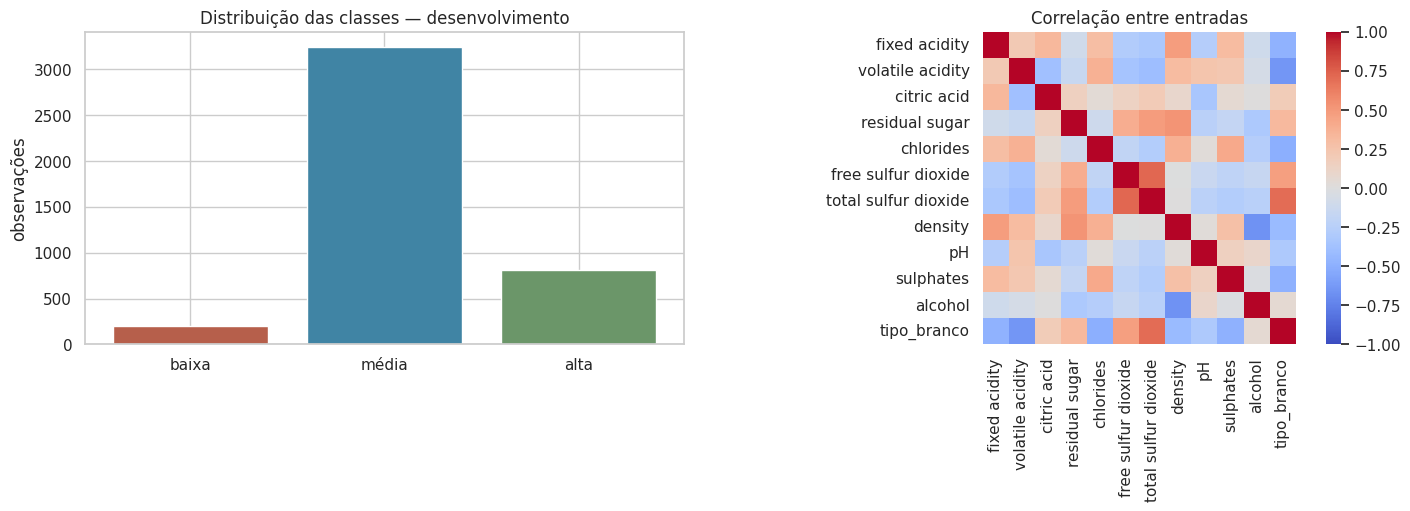

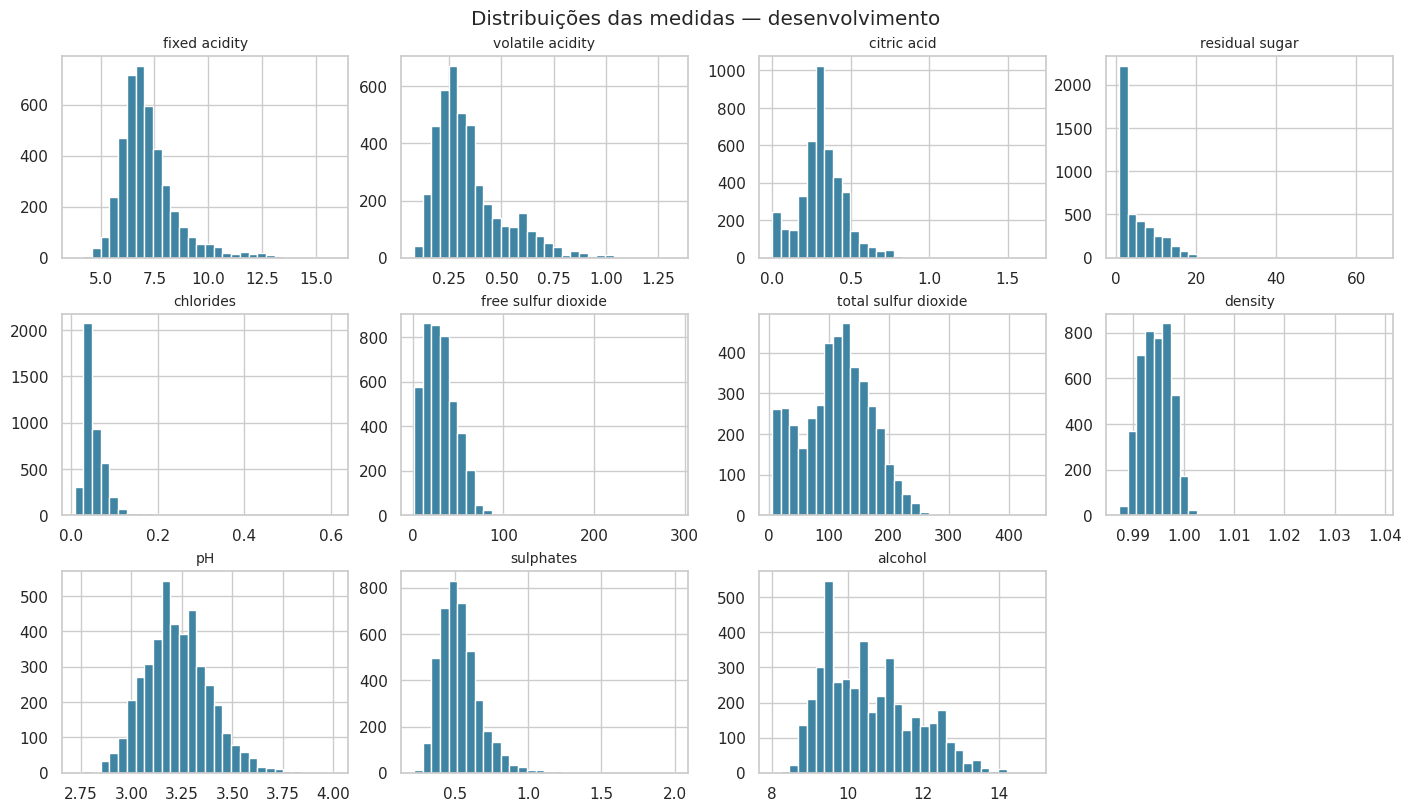

In [4]:
exploracao = X.iloc[idx_dev]
classes_dev = pd.Series(y[idx_dev]).value_counts().reindex([0,1,2], fill_value=0)
display(pd.DataFrame({
    "classe": NOMES, "quantidade": classes_dev.to_numpy(),
    "percentual": (100 * classes_dev / len(idx_dev)).to_numpy()
}).round(2))
display(pd.DataFrame({
    "ausentes": exploracao.isna().sum(),
    "valores_distintos": exploracao.nunique(),
    "minimo": exploracao.min(), "mediana": exploracao.median(),
    "maximo": exploracao.max(),
}).round(4))
print("Colunas idênticas no desenvolvimento:", int(exploracao.T.duplicated().sum()))
corr = exploracao.corr()
pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pares = pares.loc[pares.abs().sort_values(ascending=False).index]
display(pares[pares.abs() >= .70].rename("r").to_frame())
fig, ax = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
ax[0].bar(NOMES, classes_dev.to_numpy(), color=["#b65f4b", "#4084a4", "#6b9669"])
ax[0].set(title="Distribuição das classes — desenvolvimento", ylabel="observações")
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1], square=True)
ax[1].set_title("Correlação entre entradas")
figura("01_classes_correlacao")
fig, axs = plt.subplots(3, 4, figsize=(14, 8), layout="constrained")
for ax, coluna in zip(axs.flat, NUMERICAS):
    ax.hist(exploracao[coluna].dropna(), bins=30, color="#4084a4")
    ax.set_title(coluna, fontsize=10)
for ax in list(axs.flat)[len(NUMERICAS):]:
    ax.axis("off")
fig.suptitle("Distribuições das medidas — desenvolvimento")
figura("02_distribuicoes")

## 5. Pré-processamento, métricas e pesos de classe

**Ausentes:** a mediana de cada atributo numérico é aprendida só no treino.
Se não houver ausentes, esse passo não substitui valores. **Padronização:**
subtrai a média e divide pelo desvio-padrão do treino, para evitar que diferenças
de escala dificultem a otimização. O indicador de tipo permanece 0 ou 1.

**Balanceamento por pesos:** erros em classes raras podem receber mais
importância. Para classe c, com n_c exemplos num treino de N linhas, a base é
N/(3 n_c). Testamos expoentes 0 (todos iguais), 0,5 (efeito moderado) e 1
(balanceado). Normalizamos pela frequência das classes para que o **peso médio
por observação seja 1**; não pela média simples dos três pesos.
Isso controla a escala da perda ao comparar intensidades.

Não geramos vinhos sintéticos com SMOTE nesta versão: os pesos já permitem
investigar o desbalanceamento sem supor que interpolar medições de vinhos raros
gere exemplos representativos. A escolha de pesos será avaliada, não imposta.

**Accuracy:** proporção total de acertos. **Precisão:** entre as previsões de
uma classe, quantas estavam certas. **Recall:** entre os exemplos reais dessa
classe, quantos foram encontrados. **F1:** equilíbrio entre precisão e recall.
**Macro:** média com o mesmo peso para cada classe. **Weighted:** média ponderada
pelo número de exemplos. Também mostramos accuracy balanceada, a média dos recalls.

### Leitura da célula: preparar sem compartilhar estatísticas de avaliação

O pipeline numérico contém mediana e StandardScaler, ajustados somente nos índices de treino recebidos. O tipo permanece em 0/1. Na ablação de correlação, usamos Pearson absoluto ≥0,70 e mantemos a primeira coluna pela ordem definida; o limiar e essa ordem são escolhas operacionais, não testes de importância.

Para classe com frequência `n_c`, o peso é proporcional a `(n / (3 n_c)) ** alpha`, normalizado para média ponderada igual a 1. Com alpha=0 não há ponderação; 0,5 suaviza a diferença; 1 usa ponderação inversa completa. O peso altera o custo de errar, sem criar exemplos ou equilibrar contagens.

As métricas incluem macro, ponderadas e resultados da classe baixa. `zero_division=0` define zero quando uma razão não tem denominador, evitando falha no relatório, mas não resolve a ausência de previsões daquela classe.

In [5]:
def preparar(indices_fit, config):
    numericas = NUMERICAS.copy()
    removidas = []
    if config["atributos"] == "sem_correlacionados":
        matriz = X.iloc[indices_fit][numericas].corr().abs()
        mantidas = []
        for c in numericas:
            if any(matriz.loc[c, anterior] >= .70 for anterior in mantidas):
                removidas.append(c)
            else:
                mantidas.append(c)
        numericas = mantidas
    pipe_numerico = Pipeline([
        ("mediana", SimpleImputer(strategy="median")),
        ("escala", StandardScaler()),
    ])
    passos = [("numericos", pipe_numerico, numericas)]
    colunas = numericas.copy()
    if config["atributos"] != "sem_tipo":
        passos.append(("tipo", "passthrough", ["tipo_branco"]))
        colunas.append("tipo_branco")
    else:
        removidas.append("tipo_branco")
    transformador = ColumnTransformer(passos, remainder="drop")
    transformador.fit(X.iloc[indices_fit])
    return transformador, colunas, removidas

def pesos_classes(rotulos, alpha):
    contagens = np.bincount(rotulos, minlength=3)
    if np.any(contagens == 0): raise ValueError("Treino sem uma das classes.")
    w = (len(rotulos) / (3 * contagens)) ** alpha
    w /= np.average(w, weights=contagens)
    assert np.isclose(np.average(w, weights=contagens), 1.0)
    return {i: float(w[i]) for i in range(3)}

def metricas(real, previsto):
    p, r, f, n = precision_recall_fscore_support(
        real, previsto, labels=[0,1,2], zero_division=0
    )
    saida = {
        "accuracy": accuracy_score(real, previsto),
        "balanced_accuracy": balanced_accuracy_score(real, previsto),
        "precision_macro": p.mean(), "recall_macro": r.mean(), "f1_macro": f.mean(),
        "precision_weighted": np.average(p, weights=n),
        "recall_weighted": np.average(r, weights=n),
        "f1_weighted": np.average(f, weights=n),
    }
    for i, nome in enumerate(["baixa", "media", "alta"]):
        saida.update({f"precision_{nome}": p[i], f"recall_{nome}": r[i],
                      f"f1_{nome}": f[i]})
    return {k: float(v) for k, v in saida.items()}

display(pd.DataFrame({
    f"expoente_{a}": pesos_classes(y[DIVISOES[0][0]], a)
    for a in [0.0, 0.5, 1.0]
}).rename(index=dict(enumerate(NOMES))).round(3))

,expoente_0.0,expoente_0.5,expoente_1.0
baixa,1.0,2.944,6.753
média,1.0,0.749,0.437
alta,1.0,1.512,1.780


## 6. Rede e processo de treinamento

A referência é **12 → 64 → Dropout(20%) → 32 → 3**. A quantidade de entradas
pode diminuir nas ablações. Uma camada densa combina todas as entradas com
pesos aprendidos. ReLU permite relações não lineares; será comparada com Tanh
na segunda etapa. Softmax produz três probabilidades que somam 1 e a maior
define a classe. Esses escores não foram calibrados como probabilidades confiáveis.

Dropout zera aleatoriamente parte das ativações no treino para reduzir dependências
entre neurônios. Ele é aplicado após a primeira camada, como na rede anterior.
Na inferência é desligado. O teste sem Dropout verifica se ele é útil aqui.
L2 acrescenta uma penalidade para pesos grandes; será testada isoladamente.

A entropia cruzada categórica esparsa penaliza a probabilidade atribuída à classe
correta; “esparsa” indica rótulos inteiros 0, 1 e 2. Adam usa os gradientes para
atualizar os pesos. Mantemos taxa inicial 0,001 e lote 64 para controlar a
comparação. São pontos de partida, não valores teoricamente ótimos.

Treinamos por até 150 épocas. Early stopping monitora a perda no bloco interno,
espera 18 épocas sem melhoria e restaura os melhores pesos. Uma variante reduz
a taxa pela metade após 6 épocas sem melhora, até 0,00001. A paciência maior
da parada permite tentar melhorar após a redução. O teto é um orçamento
computacional; atingir 150 não comprova convergência.

As curvas finais mostram também entropia cruzada **sem pesos de classe, sem L2
e com Dropout desligado** nos dois conjuntos. Assim, as duas curvas de erro
são comparáveis. A perda usada pela otimização, com pesos e penalidade, continua
salva no histórico e controla o early stopping.

### Leitura da célula: construir, otimizar e registrar curvas comparáveis

As camadas densas usam a ativação escolhida e, quando solicitado, penalidade L2 nos pesos. Dropout é aplicado após a primeira camada e desliga-se na inferência. A saída Softmax tem três unidades. Adam inicia em 0,001; a perda usa rótulos inteiros e pesos de classe.

L2 desencoraja pesos grandes; dropout perturba ativações; reduzir a taxa altera os passos do otimizador. São mecanismos diferentes, avaliados em ablações. Early stopping monitora `val_loss`, espera 18 épocas e restaura os melhores pesos. Na variante de redução, a taxa cai pela metade após seis épocas sem melhora.

`CurvasComparaveis` calcula, ao fim de cada época, entropia cruzada sem ponderação e sem L2 nos dois conjuntos, com dropout desligado. Isso permite comparar treino e monitoramento sob a mesma definição. A curva comparável não é idêntica à perda ponderada que controla a parada. Registrar previsões a cada época acrescenta custo computacional, mas melhora a interpretação.

In [ ]:
def criar_modelo(n_entradas, config):
    rede = keras.Sequential([keras.Input(shape=(n_entradas,))], name="mlp_vinhos")
    for i, unidades in enumerate(config["camadas"]):
        rede.add(layers.Dense(
            unidades, activation=config["ativacao"],
            kernel_regularizer=regularizers.l2(config["l2"]) if config["l2"] else None,
            name=f"oculta_{i+1}",
        ))
        if i == 0 and config["dropout"] > 0:
            rede.add(layers.Dropout(config["dropout"], name="dropout"))
    rede.add(layers.Dense(3, activation="softmax", name="classes"))
    rede.compile(optimizer=keras.optimizers.Adam(learning_rate=.001),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return rede

class RegistroTaxa(keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.valores = []
    def on_epoch_end(self, epoch, logs=None):
        self.valores.append(float(keras.backend.get_value(self.model.optimizer.learning_rate)))

class CurvasComparaveis(keras.callbacks.Callback):
    def __init__(self, xt, yt, xv, yv):
        super().__init__()
        self.conjuntos = {"treino": (xt, yt), "monitoramento": (xv, yv)}
        self.valores = {f"{m}_{s}": [] for s in self.conjuntos for m in ["ce", "accuracy", "f1"]}
    def on_epoch_end(self, epoch, logs=None):
        for nome, (xx, yy) in self.conjuntos.items():
            pp = np.asarray(self.model(xx, training=False))
            mm = metricas(yy, pp.argmax(1))
            self.valores[f"ce_{nome}"].append(float(log_loss(yy, pp, labels=[0,1,2])))
            self.valores[f"accuracy_{nome}"].append(mm["accuracy"])
            self.valores[f"f1_{nome}"].append(mm["f1_macro"])

def treinar(config, idx_fit, idx_monitor, seed, curvas=False):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    prep, colunas, removidas = preparar(idx_fit, config)
    xt = prep.transform(X.iloc[idx_fit]).astype("float32")
    xm = prep.transform(X.iloc[idx_monitor]).astype("float32")
    rede = criar_modelo(xt.shape[1], config)
    taxa = RegistroTaxa()
    callbacks = [taxa, keras.callbacks.TerminateOnNaN()]
    if config["reduzir_lr"]:
        callbacks.append(keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=.5, patience=6, min_lr=1e-5))
    callbacks.append(keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PACIENCIA, restore_best_weights=True))
    observador = None
    if curvas:
        observador = CurvasComparaveis(xt, y[idx_fit], xm, y[idx_monitor])
        callbacks.append(observador)
    inicio = time.perf_counter()
    hist = rede.fit(
        xt, y[idx_fit], validation_data=(xm, y[idx_monitor]),
        epochs=MAX_EPOCAS, batch_size=LOTE, shuffle=True,
        class_weight=pesos_classes(y[idx_fit], config["alpha"]),
        callbacks=callbacks, verbose=0,
    )
    historia = {k: [float(v) for v in valores] for k, valores in hist.history.items()}
    historia["learning_rate"] = taxa.valores
    if observador is not None:
        historia.update(observador.valores)
    if not np.isfinite(historia["val_loss"]).all():
        raise RuntimeError("Perda não finita: interrompa e investigue esta configuração.")
    info = {
        "historico": historia, "epocas": len(historia["loss"]),
        "melhor_epoca": int(np.argmin(historia["val_loss"]) + 1),
        "segundos": time.perf_counter() - inicio, "parametros": rede.count_params(),
        "colunas": colunas, "removidas": removidas,
        "pesos": pesos_classes(y[idx_fit], config["alpha"]),
    }
    return rede, prep, info

## 7. Comparação de arquiteturas e balanceamento

| Candidata | Hipótese investigada |
|---|---|
| 64 | Uma camada escondida já basta? |
| 32–16 | Uma rede menor alcança resultado próximo? |
| 64–32 | Referência do notebook anterior |
| 128–64 | Mais largura acrescenta capacidade útil? |

Cada arquitetura é cruzada com pesos de expoente 0, 0,5 e 1. São 12 candidatas,
com três folds cada: 36 treinos. Na segunda etapa, fazemos seis ablações
isoladas na candidata escolhida: mais 18 treinos. Isso não cobre todas as
interações possíveis entre técnicas.

**Regra fixada antes dos resultados:** maximizar o F1 macro médio de validação.
Dentro de uma faixa de 0,005 do melhor F1, preferir menos parâmetros, depois
menos alterações extras, depois maior F1. A margem é uma tolerância prática de
meio ponto percentual, não evidência de equivalência estatística. Ela evita
defender uma rede muito maior por um ganho decimal desprezível.

Os folds e sementes são iguais entre candidatas. O conjunto de teste não é
consultado nesta etapa. Accuracy e os resultados da classe baixa são registrados
para explicar o custo da escolha, mas não mudamos o critério depois de olhar os números.

### Leitura da célula: comparar arquiteturas e intensidade dos pesos

As quatro arquiteturas são cruzadas com alpha=0, 0,5 e 1, formando 12 candidatas. Cada candidata passa pelos mesmos três folds e sementes correspondentes: 36 treinamentos na primeira etapa. O cache identifica resultados por configuração e protocolo para evitar repetir trabalhos já disponíveis.

A regra prioriza F1 macro médio, admite candidatas até 0,005 abaixo do maior valor e prefere menos parâmetros, depois menos alterações e depois maior F1. Na execução, 128–64 obteve F1 0,5601, mas 64 obteve 0,5588 com 1.027 parâmetros contra 10.115. A rede 64 foi escolhida dentro da margem. Isso justifica simplicidade no experimento, sem declarar equivalência estatística entre as redes.

In [6]:
ARQUITETURAS = {
    "uma_64": [64], "menor_32_16": [32,16],
    "base_64_32": [64,32], "larga_128_64": [128,64],
}
if not COMPLETO:
    ARQUITETURAS = {k: v for k,v in ARQUITETURAS.items()
                    if k in ["uma_64", "base_64_32"]}
ALPHAS = [0.0, .5, 1.0] if COMPLETO else [0.0, 1.0]
CONFIGS = {}
for nome, camadas in ARQUITETURAS.items():
    for alpha in ALPHAS:
        identificador = f"{nome}__peso_{alpha}"
        CONFIGS[identificador] = {
            "camadas": camadas, "dropout": .2, "ativacao": "relu",
            "l2": 0.0, "reduzir_lr": False, "alpha": alpha,
            "atributos": "todos", "extras": 0,
        }
BASE_ID = "base_64_32__peso_1.0"
ids_etapa1 = list(CONFIGS)

def chave_cache(objeto):
    conteudo = json.dumps({"protocolo": PROTOCOLO, **objeto},
                         sort_keys=True, ensure_ascii=False).encode("utf-8")
    return hashlib.sha256(conteudo).hexdigest()[:24]

def avaliar_cv(identificador):
    config = CONFIGS[identificador]
    registros = []
    for fold, (a,b,c) in enumerate(DIVISOES):
        assert set(c).issubset(set(idx_dev))
        seed = 1000 + fold
        chave = chave_cache({"config": config, "fold": fold, "seed": seed, "fase": "cv"})
        path = PASTA / "cache" / f"{chave}.json"
        if path.exists():
            registro = json.loads(path.read_text(encoding="utf-8"))
            origem = "cache"
        else:
            rede, prep, info = treinar(config, a, b, seed)
            xx = prep.transform(X.iloc[c]).astype("float32")
            probs = np.asarray(rede(xx, training=False))
            registro = {
                "id": identificador, "fold": fold+1, **metricas(y[c], probs.argmax(1)),
                **info,
            }
            salvar_json(path, registro)
            del rede, prep
            origem = "treinado"
        # O nome descritivo pode mudar sem mudar a configuração.
        registro["id"] = identificador
        registros.append(registro)
        print(f"{identificador} | fold {fold+1}/{N_FOLDS} | "
              f"F1={registro['f1_macro']:.3f} | épocas={registro['epocas']} | {origem}",
              flush=True)
    return registros

def resumir(registros):
    df = pd.DataFrame(registros)
    resumo = df.groupby("id", as_index=False).agg(
        f1_medio=("f1_macro", "mean"), f1_dp=("f1_macro", "std"),
        accuracy_media=("accuracy", "mean"), precision_baixa=("precision_baixa", "mean"),
        recall_baixa=("recall_baixa", "mean"), f1_baixa=("f1_baixa", "mean"),
        parametros=("parametros", "mean"), epocas_media=("epocas", "mean"),
    )
    resumo["extras"] = resumo["id"].map(lambda k: CONFIGS[k]["extras"])
    return resumo.sort_values("f1_medio", ascending=False).reset_index(drop=True)

def selecionar(resumo):
    limite = resumo["f1_medio"].max() - MARGEM_PRATICA
    elegiveis = resumo[resumo["f1_medio"] >= limite]
    return elegiveis.sort_values(
        ["parametros", "extras", "f1_medio", "id"],
        ascending=[True, True, False, True]
    ).iloc[0]["id"]

registros_cv = []
for identificador in ids_etapa1:
    registros_cv.extend(avaliar_cv(identificador))
resumo1 = resumir(registros_cv)
vencedor1 = selecionar(resumo1)
display(resumo1.round(4))
print("Selecionada na etapa 1:", vencedor1, CONFIGS[vencedor1])

uma_64__peso_0.0 | fold 1/3 | F1=0.429 | épocas=69 | treinado
uma_64__peso_0.0 | fold 2/3 | F1=0.459 | épocas=114 | treinado
uma_64__peso_0.0 | fold 3/3 | F1=0.520 | épocas=137 | treinado
uma_64__peso_0.5 | fold 1/3 | F1=0.529 | épocas=90 | treinado
uma_64__peso_0.5 | fold 2/3 | F1=0.572 | épocas=131 | treinado
uma_64__peso_0.5 | fold 3/3 | F1=0.575 | épocas=89 | treinado
uma_64__peso_1.0 | fold 1/3 | F1=0.488 | épocas=87 | treinado
uma_64__peso_1.0 | fold 2/3 | F1=0.487 | épocas=121 | treinado
uma_64__peso_1.0 | fold 3/3 | F1=0.518 | épocas=150 | treinado
menor_32_16__peso_0.0 | fold 1/3 | F1=0.439 | épocas=88 | treinado
menor_32_16__peso_0.0 | fold 2/3 | F1=0.431 | épocas=70 | treinado
menor_32_16__peso_0.0 | fold 3/3 | F1=0.462 | épocas=91 | treinado
menor_32_16__peso_0.5 | fold 1/3 | F1=0.527 | épocas=97 | treinado
menor_32_16__peso_0.5 | fold 2/3 | F1=0.542 | épocas=110 | treinado
menor_32_16__peso_0.5 | fold 3/3 | F1=0.576 | épocas=108 | treinado
menor_32_16__peso_1.0 | fold 1/3 

,id,f1_medio,f1_dp,accuracy_media,precision_baixa,recall_baixa,f1_baixa,parametros,epocas_media,extras
0,larga_128_64__peso_0.5,0.5601,0.0127,0.7545,0.3127,0.2742,0.2885,10115.0,58.6667,0
1,uma_64__peso_0.5,0.5588,0.0258,0.7571,0.3301,0.2699,0.2937,1027.0,103.3333,0
2,base_64_32__peso_0.5,0.5541,0.0150,0.7557,0.3497,0.2336,0.2791,3011.0,70.3333,0
3,menor_32_16__peso_0.5,0.5485,0.0253,0.7463,0.2877,0.2516,0.2683,995.0,105.0000,0
4,base_64_32__peso_1.0,0.5224,0.0149,0.6406,0.1983,0.5400,0.2887,3011.0,104.3333,0
5,larga_128_64__peso_1.0,0.5204,0.0047,0.6488,0.1909,0.4884,0.2727,10115.0,87.6667,0
6,uma_64__peso_1.0,0.4976,0.0177,0.6063,0.1637,0.5856,0.2543,1027.0,119.3333,0
7,menor_32_16__peso_1.0,0.4892,0.0160,0.5929,0.1591,0.5809,0.2482,995.0,108.0000,0
8,base_64_32__peso_0.0,0.4740,0.0267,0.7872,0.4115,0.0505,0.0886,3011.0,61.0000,0
9,larga_128_64__peso_0.0,0.4733,0.0343,0.7869,0.3016,0.0509,0.0870,10115.0,42.0000,0


Selecionada na etapa 1: uma_64__peso_0.5 {'camadas': [64], 'dropout': 0.2, 'ativacao': 'relu', 'l2': 0.0, 'reduzir_lr': False, 'alpha': 0.5, 'atributos': 'todos', 'extras': 0}


## 8. Ablações para explicar as técnicas e os atributos

Cada candidata abaixo altera **um componente** da selecionada na etapa anterior.
Nenhuma combinação de mudanças será usada sem ter sido treinada e avaliada.

| Alteração | O que permite responder |
|---|---|
| Dropout = 0 | Desativar 20% das ativações realmente ajudava? |
| L2 = 0,0001 | Penalizar pesos grandes melhora a generalização? |
| Redução da taxa | Dar passos menores quando a perda estagna ajuda? |
| Tanh em lugar de ReLU | A ativação faz diferença nesta rede tabular? |
| Retirar correlacionados | A redundância atrapalha ou ainda contém informação útil? |
| Retirar tipo | O indicador tinto/branco contribui? |

Na ablação de correlação, a análise é refeita só no treino de cada fold. Para
pares acima de 0,70, mantemos primeiro a coluna que aparece antes na ordem
original do arquivo. É uma regra estável para o teste, não uma afirmação de
que aquela medida seja mais importante. As colunas retiradas ficam registradas.

Os resultados das duas etapas são reunidos e a mesma regra de seleção é aplicada.
Como as ablações partem de uma candidata escolhida, a busca é adaptativa;
o teste final ajuda a avaliar o possível otimismo de escolher entre alternativas.

### Leitura da célula: testar uma alteração por vez e congelar a decisão

As seis ablações mudam isoladamente dropout, L2, redução de taxa, ativação, atributos correlacionados ou tipo. São 18 treinamentos adicionais, totalizando 54 na validação. O ponto de partida é a configuração escolhida na primeira etapa, não todas as combinações possíveis.

Retirar dropout obteve F1 médio 0,5646 ± 0,0140, contra 0,5588 na etapa anterior. Retirar correlacionados obteve 0,5537, retirar tipo 0,5426, usar Tanh 0,5567, L2 0,5593 e reduzir taxa 0,5494. Esses resultados orientam manter todos os atributos, ReLU e taxa fixa, retirando dropout. A melhoria sem dropout é pequena e não constitui prova estatística.

A configuração final é **12 → 64 ReLU → 3 Softmax**, alpha=0,5, sem dropout ou L2. Salvamos a decisão antes de consultar o teste. A busca é finita e adaptativa: as ablações dependem de uma escolha anterior, e não permitem afirmar ausência de interações entre técnicas.

ablacao__sem_dropout | fold 1/3 | F1=0.549 | épocas=69 | treinado
ablacao__sem_dropout | fold 2/3 | F1=0.568 | épocas=104 | treinado
ablacao__sem_dropout | fold 3/3 | F1=0.576 | épocas=150 | treinado
ablacao__l2_suave | fold 1/3 | F1=0.529 | épocas=90 | treinado
ablacao__l2_suave | fold 2/3 | F1=0.575 | épocas=131 | treinado
ablacao__l2_suave | fold 3/3 | F1=0.574 | épocas=89 | treinado
ablacao__reduzir_taxa | fold 1/3 | F1=0.524 | épocas=55 | treinado
ablacao__reduzir_taxa | fold 2/3 | F1=0.558 | épocas=80 | treinado
ablacao__reduzir_taxa | fold 3/3 | F1=0.566 | épocas=53 | treinado
ablacao__ativacao_tanh | fold 1/3 | F1=0.533 | épocas=125 | treinado
ablacao__ativacao_tanh | fold 2/3 | F1=0.565 | épocas=137 | treinado
ablacao__ativacao_tanh | fold 3/3 | F1=0.572 | épocas=150 | treinado
ablacao__retirar_correlacionados | fold 1/3 | F1=0.530 | épocas=93 | treinado
ablacao__retirar_correlacionados | fold 2/3 | F1=0.562 | épocas=121 | treinado
ablacao__retirar_correlacionados | fold 3/3 |

,id,f1_medio,f1_dp,accuracy_media,precision_baixa,recall_baixa,f1_baixa,parametros,epocas_media,extras
0,ablacao__sem_dropout,0.5646,0.0140,0.7555,0.3008,0.3060,0.3013,1027.0000,107.6667,1
1,larga_128_64__peso_0.5,0.5601,0.0127,0.7545,0.3127,0.2742,0.2885,10115.0000,58.6667,0
2,ablacao__l2_suave,0.5593,0.0261,0.7578,0.3279,0.2699,0.2928,1027.0000,103.3333,1
3,uma_64__peso_0.5,0.5588,0.0258,0.7571,0.3301,0.2699,0.2937,1027.0000,103.3333,0
4,ablacao__ativacao_tanh,0.5567,0.0212,0.7531,0.3323,0.2595,0.2910,1027.0000,137.3333,1
5,base_64_32__peso_0.5,0.5541,0.0150,0.7557,0.3497,0.2336,0.2791,3011.0000,70.3333,0
6,ablacao__retirar_correlacionados,0.5537,0.0204,0.7510,0.3271,0.2809,0.3000,941.6667,109.3333,1
7,ablacao__reduzir_taxa,0.5494,0.0223,0.7536,0.3298,0.2386,0.2746,1027.0000,62.6667,1
8,menor_32_16__peso_0.5,0.5485,0.0253,0.7463,0.2877,0.2516,0.2683,995.0000,105.0000,0
9,ablacao__retirar_tipo,0.5426,0.0293,0.7526,0.2859,0.2277,0.2520,963.0000,109.0000,1


Configuração congelada antes do teste: ablacao__sem_dropout {'camadas': [64], 'dropout': 0.0, 'ativacao': 'relu', 'l2': 0.0, 'reduzir_lr': False, 'alpha': 0.5, 'atributos': 'todos', 'extras': 1}


,id,delta_f1_vs_etapa1,precision_baixa,recall_baixa
0,ablacao__sem_dropout,0.0058,0.3008,0.3060
2,ablacao__l2_suave,0.0004,0.3279,0.2699
4,ablacao__ativacao_tanh,-0.0021,0.3323,0.2595
6,ablacao__retirar_correlacionados,-0.0051,0.3271,0.2809
7,ablacao__reduzir_taxa,-0.0094,0.3298,0.2386
9,ablacao__retirar_tipo,-0.0162,0.2859,0.2277


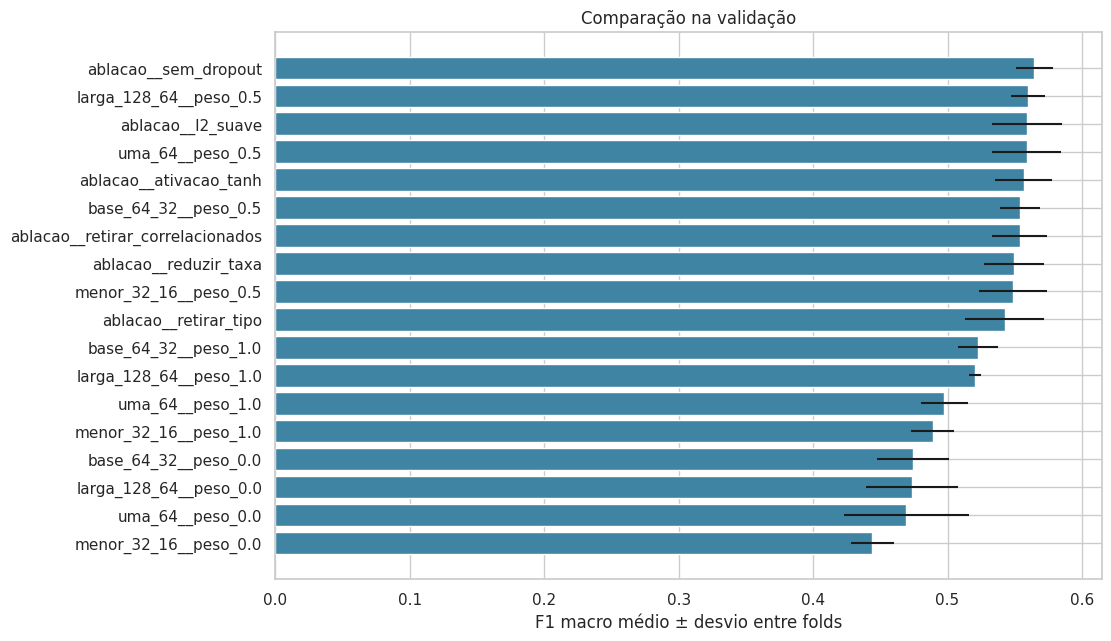

In [7]:
alteracoes = {
    "sem_dropout": {"dropout": 0.0},
    "l2_suave": {"l2": 1e-4},
    "reduzir_taxa": {"reduzir_lr": True},
    "ativacao_tanh": {"ativacao": "tanh"},
    "retirar_correlacionados": {"atributos": "sem_correlacionados"},
    "retirar_tipo": {"atributos": "sem_tipo"},
}
for nome, mudanca in alteracoes.items():
    identificador = f"ablacao__{nome}"
    CONFIGS[identificador] = {**CONFIGS[vencedor1], **mudanca, "extras": 1}
    registros_cv.extend(avaliar_cv(identificador))
resumo_cv = resumir(registros_cv)
ESCOLHIDO_ID = selecionar(resumo_cv)
ESCOLHIDO = CONFIGS[ESCOLHIDO_ID]
salvar_json(PASTA / "escolha_antes_teste.json", {
    "id": ESCOLHIDO_ID, "config": ESCOLHIDO,
    "criterio": "F1 macro médio; faixa 0,005; menor número de parâmetros",
    "todos_candidatos": CONFIGS,
})
resumo_cv.to_csv(PASTA / "comparacao_validacao.csv", index=False)
pd.DataFrame([{k:v for k,v in r.items() if k != "historico"} for r in registros_cv]).to_csv(
    PASTA / "resultados_por_fold.csv", index=False)
display(resumo_cv.round(4))
print("Configuração congelada antes do teste:", ESCOLHIDO_ID, ESCOLHIDO)
f1_referencia = resumo_cv.set_index("id").loc[vencedor1, "f1_medio"]
efeitos = resumo_cv[resumo_cv["id"].str.startswith("ablacao")].copy()
efeitos["delta_f1_vs_etapa1"] = efeitos["f1_medio"] - f1_referencia
display(efeitos[["id", "delta_f1_vs_etapa1", "precision_baixa", "recall_baixa"]].round(4))
fig, ax = plt.subplots(figsize=(11, max(5, len(resumo_cv)*.35)), layout="constrained")
ax.barh(resumo_cv["id"], resumo_cv["f1_medio"],
        xerr=resumo_cv["f1_dp"].fillna(0), color="#4084a4")
ax.invert_yaxis()
ax.set(xlabel="F1 macro médio ± desvio entre folds", title="Comparação na validação")
figura("03_comparacao_validacao")

## 9. Ajuste final e teste

A escolha está congelada. Criamos um treino final e um monitoramento dentro
do desenvolvimento, aproximadamente 64% e 16% do conjunto total; o teste
continua com aproximadamente 20%. O early stopping é mantido, então não
treinamos com todo o desenvolvimento junto.

A MLP selecionada e a referência são treinadas com sementes 42, 123 e 2026.
Publicamos a média e o desvio entre essas inicializações no mesmo teste.
Para arquitetura, curvas e matrizes individuais, usamos **semente 42,
definida antes dos resultados**, sem escolher a melhor semente pelo teste.

Também avaliamos prever sempre a classe majoritária do treino e uma regressão
logística balanceada, um classificador linear. Essas referências mostram
se a complexidade da MLP acrescentou algo. A logística tem regularização padrão
C=1 e não recebe uma busca própria de parâmetros.

O resultado do teste não troca a configuração escolhida. Uma melhoria de
validação que não se confirma no teste deve ser relatada, não escondida.

### Leitura da célula: avaliar a solução escolhida e referências

Treinamos a escolhida e a referência 64–32 com dropout 0,2 e alpha=1 usando sementes 42, 123 e 2026. O treino final continua separado de um monitoramento interno; portanto, nem todos os 4.257 exemplos de desenvolvimento ajustam pesos. O teste só recebe a transformação aprendida no treino final.

São salvos modelo Keras, pipeline, probabilidades, índices, histórico e métricas. Esses arquivos são gerados quando o notebook é executado; saídas embutidas no `.ipynb` não substituem os arquivos de pesos. As referências adicionais são sempre prever a classe majoritária e regressão logística balanceada. Esta última não recebe busca própria de hiperparâmetros.

A tabela agrega três sementes no mesmo teste. Isso mede sensibilidade do treinamento, não três amostras externas. Não trocamos o modelo após observar essa tabela. O melhor F1 da escolhida deve ser examinado junto com a queda de recall em relação à referência mais fortemente ponderada.

In [8]:
def executar_final(identificador, seed):
    config = CONFIGS[identificador]
    chave = chave_cache({"config": config, "seed": seed, "fase": "final"})
    pasta_modelo = PASTA / "modelos" / chave
    pasta_modelo.mkdir(exist_ok=True)
    path = pasta_modelo / "resultado.json"
    if path.exists():
        registro = json.loads(path.read_text(encoding="utf-8"))
        probs = np.load(pasta_modelo / "previsoes.npz")["probabilidades"]
        registro["id"] = identificador
        return registro, probs
    rede, prep, info = treinar(config, idx_final_fit, idx_final_monitor, seed, curvas=True)
    xteste = prep.transform(X.iloc[idx_teste]).astype("float32")
    probs = np.asarray(rede(xteste, training=False))
    linhas = []
    rede.summary(print_fn=lambda texto: linhas.append(texto))
    registro = {
        "id": identificador, "seed": seed,
        **metricas(y[idx_teste], probs.argmax(1)), **info,
        "summary": "\n".join(linhas), "pasta_modelo": str(pasta_modelo),
    }
    rede.save(pasta_modelo / "modelo.keras")
    joblib.dump(prep, pasta_modelo / "preprocessamento.joblib")
    np.savez_compressed(pasta_modelo / "previsoes.npz",
                        probabilidades=probs, indices=idx_teste, reais=y[idx_teste])
    salvar_json(path, registro)
    del rede, prep
    return registro, probs

registros_finais = []
probabilidades_finais = {}
for identificador in dict.fromkeys([BASE_ID, ESCOLHIDO_ID]):
    for seed in SEMENTES_FINAIS:
        registro, probs = executar_final(identificador, seed)
        registros_finais.append(registro)
        probabilidades_finais[(identificador, seed)] = probs
        print(f"Final | {identificador} | semente {seed} | F1={registro['f1_macro']:.3f}",
              flush=True)
final_df = pd.DataFrame(registros_finais)

prep_base, _, _ = preparar(idx_final_fit, CONFIGS[BASE_ID])
xa = prep_base.transform(X.iloc[idx_final_fit])
xb = prep_base.transform(X.iloc[idx_teste])
baselines = {
    "Classe majoritária": DummyClassifier(strategy="most_frequent"),
    "Logística balanceada": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000),
}
linhas_baselines = []
for nome, modelo in baselines.items():
    modelo.fit(xa, y[idx_final_fit])
    linhas_baselines.append({"id": nome, **metricas(y[idx_teste], modelo.predict(xb))})
METRICAS = [
    "accuracy", "precision_macro", "recall_macro", "f1_macro",
    "f1_weighted", "precision_baixa", "recall_baixa", "f1_baixa",
]
resumo_final = final_df.groupby("id")[METRICAS].agg(["mean", "std"])
print("MLPs: média e desvio entre sementes; mesmo teste")
display(resumo_final.round(4))
print("Referências determinísticas: uma execução")
display(pd.DataFrame(linhas_baselines).set_index("id")[METRICAS].round(4))
resumo_final.to_csv(PASTA / "metricas_teste_media_desvio.csv")
pd.DataFrame(linhas_baselines).to_csv(PASTA / "baselines_teste.csv", index=False)
final_df.drop(columns=["historico", "summary"]).to_csv(PASTA / "metricas_teste_sementes.csv", index=False)

Final | base_64_32__peso_1.0 | semente 42 | F1=0.496


Final | base_64_32__peso_1.0 | semente 123 | F1=0.521


Final | base_64_32__peso_1.0 | semente 2026 | F1=0.501


Final | ablacao__sem_dropout | semente 42 | F1=0.568


Final | ablacao__sem_dropout | semente 123 | F1=0.553


Final | ablacao__sem_dropout | semente 2026 | F1=0.587
MLPs: média e desvio entre sementes; mesmo teste


accuracy         precision_macro         recall_macro  \
                         mean     std            mean     std         mean   
id                                                                           
ablacao__sem_dropout   0.7488  0.0108          0.5466  0.0098       0.6134   
base_64_32__peso_1.0   0.6359  0.0217          0.4973  0.0068       0.6673   

                             f1_macro         f1_weighted          \
                         std     mean     std        mean     std   
id                                                                  
ablacao__sem_dropout  0.0437   0.5693  0.0171      0.7595  0.0035   
base_64_32__peso_1.0  0.0054   0.5061  0.0135      0.6771  0.0188   

                     precision_baixa         recall_baixa         f1_baixa  \
                                mean     std         mean     std     mean   
id                                                                           
ablacao__sem_dropout          0.2944  0.0296       0.4649  0.0846   0.3573   
base_64_32__peso_1.0          0.1554  0.0140       0.6228  0.0304   0.2482   

                              
                         std  
id                            
ablacao__sem_dropout  0.0317  
base_64_32__peso_1.0  0.0160

Referências determinísticas: uma execução


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,precision_baixa,recall_baixa,f1_baixa
id,,,,,,,,
Classe majoritária,0.7799,0.2600,0.3333,0.2921,0.6834,0.0000,0.0000,0.0000
Logística balanceada,0.5757,0.4841,0.6695,0.4704,0.6261,0.1211,0.7105,0.2069


## 10. Arquitetura, curvas e erros do modelo escolhido

As curvas abaixo pertencem ao treino final da semente 42. A linha vertical
marca a época com menor val_loss, cujos pesos foram restaurados. Elas mostram
o percurso até a parada, inclusive épocas posteriores ao ponto restaurado.

Curvas próximas não provam ausência de sobreajuste; curvas separadas sugerem
investigar a diferença. A matriz em contagens mostra quantos exemplos
sofreram cada erro; a normalizada por linha permite comparar recalls de classes
com tamanhos diferentes. A classe baixa merece atenção tanto no recall
quanto na precisão: encontrar mais casos pode aumentar falsos alarmes.

### Leitura da célula: arquitetura, história de aprendizado e erros concretos

Usamos a semente 42, definida como representante, para desenhar a arquitetura, as curvas e as matrizes. A rede tem **1.027 parâmetros treináveis**: `(12+1)×64 + (64+1)×3`. Resumos Keras podem incluir variáveis do otimizador no total; essas variáveis não são camadas adicionais da MLP.

A linha vertical indica a época de menor perda monitorada e os pesos restaurados. Treino melhora enquanto o monitoramento tende a estabilizar, indicando uma diferença de generalização e sinais de sobreajuste. A taxa permaneceu 0,001 na configuração escolhida. Não seria correto afirmar que ReduceLROnPlateau melhorou este modelo final.

Na matriz escolhida, acertamos 20 dos 38 casos baixos, 652 dos 829 médios e 115 dos 196 altos. Para a classe baixa, precision=0,263 e recall=0,526: encontramos cerca de metade dos casos, com muitos falsos alarmes. A accuracy desta execução é 0,740 e F1 macro 0,568. Esses números pertencem a uma semente; a média das três aparece na avaliação anterior.

Model: "mlp_vinhos"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classes (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 3,083 (12.05 KB)
 Trainable params: 1,027 (4.01 KB)
 Non-trainable params: 0 (0.00 B)
 Optimizer params: 2,056 (8.04 KB)

Entradas: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'tipo_branco']
Retiradas nesta execução: []
Pesos de classe: {0: 2.9145818981962512, 1: 0.7489010447132811, 2: 1.500701999

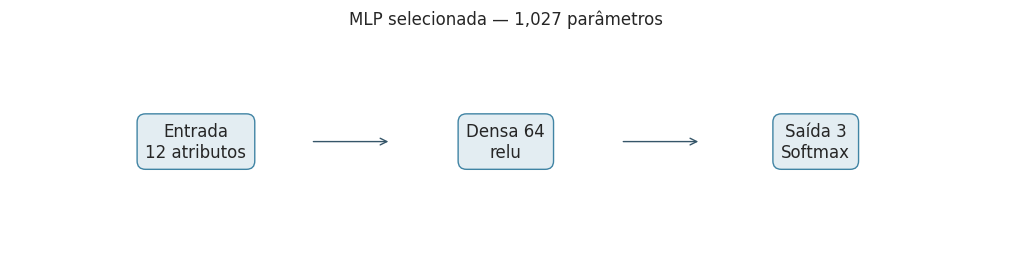

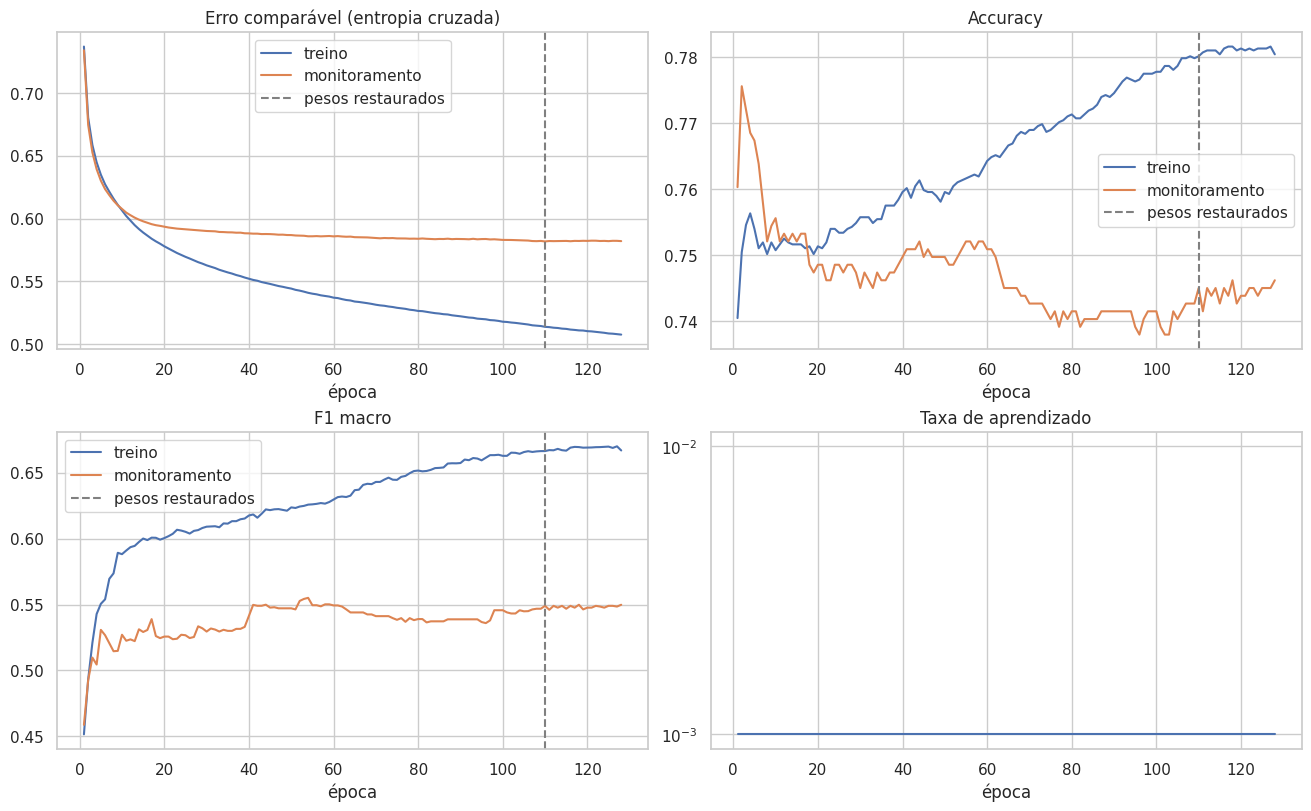

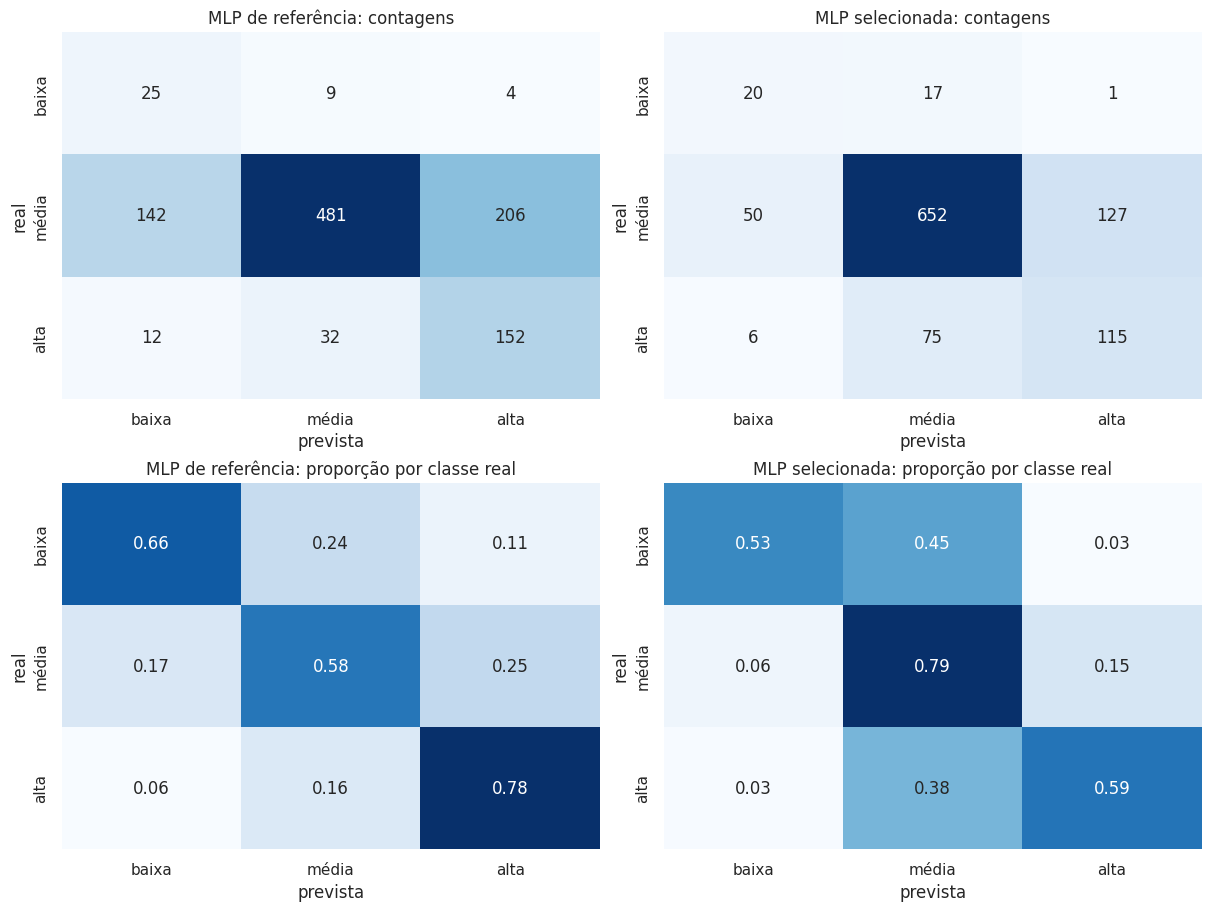

,precision,recall,f1-score,support
baixa,0.2632,0.5263,0.3509,38.0000
média,0.8763,0.7865,0.8290,829.0000
alta,0.4733,0.5867,0.5239,196.0000
accuracy,0.7404,0.7404,0.7404,0.7404
macro avg,0.5376,0.6332,0.5679,1063.0000
weighted avg,0.7801,0.7404,0.7556,1063.0000


In [9]:
representante = next(r for r in registros_finais if r["id"] == ESCOLHIDO_ID and r["seed"] == 42)
print(representante["summary"])
print("Entradas:", representante["colunas"])
print("Retiradas nesta execução:", representante["removidas"])
print("Pesos de classe:", representante["pesos"])

caixas = [f"Entrada\n{len(representante['colunas'])} atributos"]
for i, n in enumerate(ESCOLHIDO["camadas"]):
    caixas.append(f"Densa {n}\n{ESCOLHIDO['ativacao']}")
    if i == 0 and ESCOLHIDO["dropout"] > 0:
        caixas.append(f"Dropout\n{ESCOLHIDO['dropout']:.0%}")
caixas.append("Saída 3\nSoftmax")
fig, ax = plt.subplots(figsize=(max(10, len(caixas)*2), 2.5), layout="constrained")
ax.set_xlim(-.6, len(caixas)-.4)
ax.set_ylim(-.7, .7)
for i, rotulo in enumerate(caixas):
    ax.text(i, 0, rotulo, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=.5", facecolor="#e3edf2", edgecolor="#4084a4"))
    if i:
        ax.annotate("", xy=(i-.37,0), xytext=(i-1+.37,0),
                    arrowprops=dict(arrowstyle="->", color="#365669"))
ax.set_title(f"MLP selecionada — {representante['parametros']:,} parâmetros")
ax.axis("off")
figura("04_arquitetura")

h = representante["historico"]
epocas = np.arange(1, representante["epocas"]+1)
fig, axs = plt.subplots(2,2, figsize=(13,8), layout="constrained")
for ax, metrica, titulo in zip(
    axs.flat, ["ce", "accuracy", "f1"], ["Erro comparável (entropia cruzada)", "Accuracy", "F1 macro"]
):
    for conjunto in ["treino", "monitoramento"]:
        ax.plot(epocas, h[f"{metrica}_{conjunto}"], label=conjunto)
    ax.axvline(representante["melhor_epoca"], color="grey", ls="--", label="pesos restaurados")
    ax.set(title=titulo, xlabel="época")
    ax.legend()
axs[1,1].plot(epocas, h["learning_rate"])
axs[1,1].set(title="Taxa de aprendizado", xlabel="época", yscale="log")
figura("05_curvas_treinamento")

comparar_matrizes = [(BASE_ID, "MLP de referência"), (ESCOLHIDO_ID, "MLP selecionada")]
if ESCOLHIDO_ID == BASE_ID:
    comparar_matrizes = [(BASE_ID, "Selecionada: a própria referência")]
    print("A regra de seleção manteve a rede de referência; mostramos sua matriz uma vez.")
fig, axs = plt.subplots(2, len(comparar_matrizes), figsize=(6*len(comparar_matrizes),9),
                        layout="constrained", squeeze=False)
for coluna, (identificador, titulo) in enumerate(comparar_matrizes):
    pred = probabilidades_finais[(identificador,42)].argmax(1)
    cont = confusion_matrix(y[idx_teste], pred, labels=[0,1,2])
    normalizada = cont / cont.sum(axis=1, keepdims=True)
    for linha, matriz, formato, subtitulo in [
        (0,cont,"d","contagens"), (1,normalizada,".2f","proporção por classe real")
    ]:
        sns.heatmap(matriz, annot=True, fmt=formato, cmap="Blues", cbar=False,
                    xticklabels=NOMES, yticklabels=NOMES, ax=axs[linha,coluna])
        axs[linha,coluna].set(title=f"{titulo}: {subtitulo}", xlabel="prevista", ylabel="real")
figura("06_matrizes_confusao")
pred_final = probabilidades_finais[(ESCOLHIDO_ID,42)].argmax(1)
relatorio = classification_report(
    y[idx_teste], pred_final, labels=[0,1,2], target_names=NOMES,
    zero_division=0, output_dict=True
)
display(pd.DataFrame(relatorio).T.round(4))
pd.DataFrame(relatorio).T.to_csv(PASTA / "relatorio_por_classe_semente42.csv")

## 11. Interpretação produzida a partir da execução

O texto gerado abaixo usa os números atuais. Ganho no teste significa ganho
nesta partição; não garante superioridade em outras amostras. A média sobre
três sementes finais mede variação da otimização com o teste fixo.

A seleção em desenvolvimento e a avaliação final usam tamanhos de treino
diferentes. Portanto, seus valores absolutos não precisam coincidir.
Se o orçamento de épocas for atingido, isso é registrado como limite.
Nenhuma conclusão sobre dropout, pesos ou redundância deve ser atribuída
a um componente que não foi comparado isoladamente.

### Leitura da célula: transformar números em conclusão auditável

O texto é calculado a partir das tabelas atuais e salva a configuração, o ganho e os limites. No teste registrado, accuracy média passa de 0,6359 para 0,7488 e F1 macro de 0,5061 para 0,5693. A diferença de F1 é 0,0632, ou 6,32 pontos percentuais na escala de 0 a 100.

Na classe baixa, precision média aumenta de 0,1554 para 0,2944, recall cai de 0,6228 para 0,4649 e F1 sobe de 0,2482 para 0,3573. Portanto, o ganho envolve uma troca entre detectar casos e gerar falsos alarmes. Um dos três treinos finais chegou a 150 épocas, sem garantia de convergência completa.

O pacote ZIP reúne artefatos criados no ambiente, e os arquivos de partição permitem rastrear os grupos. O texto gerado não substitui inspecionar tabelas, curvas e erros por classe.

In [10]:
medias_teste = final_df.groupby("id")[METRICAS].mean()
antes = medias_teste.loc[BASE_ID]
depois = medias_teste.loc[ESCOLHIDO_ID]
ganho = float(depois["f1_macro"] - antes["f1_macro"])
frase = ("aumentou" if ganho > 0 else "diminuiu" if ganho < 0 else "permaneceu igual")
linha_escolhida = resumo_cv.set_index("id").loc[ESCOLHIDO_ID]
no_limite = int(sum(r["epocas"] == MAX_EPOCAS for r in registros_finais
                   if r["id"] == ESCOLHIDO_ID))
texto = (
    f"**Configuração selecionada:** {ESCOLHIDO_ID}. "
    f"Camadas {ESCOLHIDO['camadas']}, ativação {ESCOLHIDO['ativacao']}, "
    f"Dropout {ESCOLHIDO['dropout']:.0%}, L2 {ESCOLHIDO['l2']}, "
    f"expoente dos pesos {ESCOLHIDO['alpha']}, atributos {ESCOLHIDO['atributos']}.\n\n"
    f"Na validação, F1 macro médio {linha_escolhida['f1_medio']:.3f} "
    f"com desvio {linha_escolhida['f1_dp']:.3f} entre folds. "
    f"A escolha considerou a margem prática de {MARGEM_PRATICA:.3f} e a complexidade.\n\n"
    f"No teste, o F1 macro médio {frase}: referência {antes['f1_macro']:.3f}; "
    f"selecionada {depois['f1_macro']:.3f}; diferença {ganho:+.3f}. "
    f"Accuracy: {antes['accuracy']:.3f} → {depois['accuracy']:.3f}.\n\n"
    f"Na classe baixa, precisão {antes['precision_baixa']:.3f} → "
    f"{depois['precision_baixa']:.3f}; recall {antes['recall_baixa']:.3f} → "
    f"{depois['recall_baixa']:.3f}; F1 {antes['f1_baixa']:.3f} → {depois['f1_baixa']:.3f}. "
    f"Essas três medidas mostram o equilíbrio entre encontrar casos e gerar falsos alarmes.\n\n"
    f"{no_limite} de {len(SEMENTES_FINAIS)} treinos finais da selecionada atingiram "
    f"o teto de {MAX_EPOCAS} épocas. Não há afirmação de convergência garantida.\n\n"
    "**Limites:** busca finita e adaptativa, uma partição externa de teste, "
    "ausência de validação externa e de calibração das probabilidades. "
    "As faixas de notas são ordenadas, mas a entropia cruzada usada trata as "
    "categorias como classes; não modela explicitamente a distância entre elas."
)
if not COMPLETO:
    texto = "**EXECUÇÃO DE VERIFICAÇÃO: NÃO USAR COMO RESULTADO FINAL.**\n\n" + texto
display(Markdown(texto))
(PASTA / "interpretacao.md").write_text(texto, encoding="utf-8")
salvar_json(PASTA / "resumo_execucao.json", {
    "modo": MODO, "selecionado": ESCOLHIDO_ID, "config": ESCOLHIDO,
    "validacao": linha_escolhida.to_dict(), "teste_base": antes.to_dict(),
    "teste_selecionado": depois.to_dict(), "delta_f1": ganho,
})
rotulos_divisao = np.full(len(dados), "desenvolvimento", dtype=object)
rotulos_divisao[idx_teste] = "teste"
pd.DataFrame({"linha_deduplicada": np.arange(len(dados)), "grupo": grupos,
              "particao": rotulos_divisao}).to_csv(PASTA / "particoes.csv", index=False)
salvar_json(PASTA / "configuracoes_comparadas.json", CONFIGS)
arquivo_entrega = shutil.make_archive(str(PASTA.resolve()) + "_entrega", "zip", PASTA)
print("Pasta com figuras, métricas, modelos e históricos:", PASTA.resolve())
print("Pacote de resultados:", arquivo_entrega)

**Configuração selecionada:** ablacao__sem_dropout. Camadas [64], ativação relu, Dropout 0%, L2 0.0, expoente dos pesos 0.5, atributos todos.

Na validação, F1 macro médio 0.565 com desvio 0.014 entre folds. A escolha considerou a margem prática de 0.005 e a complexidade.

No teste, o F1 macro médio aumentou: referência 0.506; selecionada 0.569; diferença +0.063. Accuracy: 0.636 → 0.749.

Na classe baixa, precisão 0.155 → 0.294; recall 0.623 → 0.465; F1 0.248 → 0.357. Essas três medidas mostram o equilíbrio entre encontrar casos e gerar falsos alarmes.

1 de 3 treinos finais da selecionada atingiram o teto de 150 épocas. Não há afirmação de convergência garantida.

**Limites:** busca finita e adaptativa, uma partição externa de teste, ausência de validação externa e de calibração das probabilidades. As faixas de notas são ordenadas, mas a entropia cruzada usada trata as categorias como classes; não modela explicitamente a distância entre elas.

Pasta com figuras, métricas, modelos e históricos: /content/resultados_q2
Pacote de resultados: /content/resultados_q2_entrega.zip


## 12. Como defender as decisões na apresentação

**Por que esse número de neurônios?** Mostre as candidatas e a tabela de
validação. O número vem de uma escolha entre alternativas testadas, com uma
tolerância declarada para preferir modelos menores. Não é uma fórmula universal.

**Por que usar ou retirar dropout?** Mostre a diferença entre a escolhida
na etapa 1 e sua ablação sem dropout. Uma diferença pequena entre folds pede
cautela. O teste da configuração completa não prova sozinho o efeito de cada técnica.

**Por que pesos de classe?** Compare os expoentes 0, 0,5 e 1 na mesma
arquitetura. Explique a precisão e o recall da classe baixa juntos.

**Por que remover ou manter atributos?** A correlação motivou uma hipótese.
A ablação, ajustada somente com o treino, verificou seu efeito. Correlação
sozinha não determina importância preditiva.

**Por que a accuracy pode cair?** Prever mais casos raros pode reduzir os
acertos da classe mais frequente. O critério principal foi F1 macro, definido
antes dos resultados. Relate o custo em accuracy em vez de ocultá-lo.

**O modelo melhorou?** Use o texto e as tabelas da execução. Se o ganho de
validação não aparecer no teste, diga isso. Não altere a configuração para
perseguir um resultado melhor nesse mesmo teste.

| Pedido do enunciado | Onde está atendido |
|---|---|
| MLP e três faixas de qualidade | Seções 2, 6 e 10 |
| Ausentes e normalização | Seções 4 e 5 |
| Atributos redundantes | Seções 4, 5 e 8 |
| Distribuição e necessidade de balanceamento | Seções 4, 5 e 7 |
| Arquitetura utilizada | Seções 9 e 10, com resumo e diagrama |
| Erro de treino e validação | Seção 10, curvas salvas do mesmo treino |
| Matriz de confusão | Seção 10, contagens e proporções |
| Accuracy, precision, recall e F1 | Seções 9 e 10, médias e resultados por classe |

### Fontes

- Enunciado: lista_maritan.pdf, Questão 2, página 2.
- [UCI — Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality):
  origem e descrição das variáveis.
- [Scikit-Learn — StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html):
  estratificação aproximada sem misturar grupos.
- [Keras — EarlyStopping](https://keras.io/api/callbacks/early_stopping/):
  monitoramento e restauração dos melhores pesos.

## Resultado consolidado e interpretação final

| Métrica no teste | Referência 64–32 | Escolhida 64, sem dropout |
|---|---:|---:|
| Accuracy | 0,6359 ± 0,0217 | 0,7488 ± 0,0108 |
| Precision macro | 0,4973 ± 0,0068 | 0,5466 ± 0,0098 |
| Recall macro | 0,6673 ± 0,0054 | 0,6134 ± 0,0437 |
| F1 macro | 0,5061 ± 0,0135 | 0,5693 ± 0,0171 |

Os números resumem três inicializações no mesmo teste. A accuracy da referência majoritária foi 0,7799, superior à MLP, mas seu F1 macro foi apenas 0,2921, sem reconhecer classes minoritárias. Logo, a MLP atende melhor ao objetivo de considerar as três categorias, sem maximizar a taxa global de acertos. A logística balanceada obteve F1 macro 0,4704.

A classe baixa continua difícil: sua precision média é 0,2944 e F1 médio 0,3573. Dados desequilibrados, sobreposição dos atributos e informação limitada nas medições são explicações possíveis, mas este experimento não quantifica a contribuição causal de cada uma. O resultado é uma melhoria documentada do compromisso entre classes, com limitações explícitas; não é um classificador perfeito.

### Perguntas para verificar compreensão

1. Por que retirar `quality` das entradas? Porque ela define a resposta e estaria indisponível ao tentar prevê-la.
2. Por que uma camada oculta ainda é uma MLP? A rede tem entrada, transformação densa não linear e saída; MLP não exige duas camadas ocultas.
3. Por que manter atributos correlacionados? A ablação não melhorou o F1 médio; correlação isolada não basta para excluir informação.
4. Por que retirar dropout? A alteração foi testada e escolhida na validação; não significa que dropout sempre prejudique redes tabulares.
5. Por que a curva de perda e o F1 podem discordar? A perda usa os escores contínuos e o treinamento os pondera; F1 usa decisões discretas e agrega por classe.
6. A separação por grupos garante vinhos fisicamente diferentes? Ela garante a regra de igualdade das medições implementada; a base não fornece identidade física para demonstrar isso.

O estudo usa um único teste externo ao desenvolvimento e busca adaptativa. As classes são ordenadas, mas a perda categórica não trata explicitamente a distância entre baixa, média e alta.